### TEL354 - Minería de datos
# Clase 7: Spectral Clustering
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase7 import *

# Algoritmo Spectral Clustering

1. Calcular la matriz de Afinidad (Similaridad).
2. Calcular el Laplaciano y obtener sus vectores propios.
4. Proyectar los datos en un nuevo espacio definido por los primeros $K$ vectores propios.
5. Aplicar $K$-Means sobre ese nuevo espacio para formar $K$ clusters.

# Matriz de Afinidad

$\mathcal{A}_{i,j} = w_{i,j}$, donde $w_{i,j}$ es la similaridad entre $i$ y $j$.

La Matriz de Afinidad se puede calcular:
- construyendo un grafo de vecinos más cercanos (KNN).
- usando una función de base radial (RBF) como Kernel.

In [2]:
X = np.array([[0, 3], [0, 4], [3, 1], [3, 2], [4, 2]])

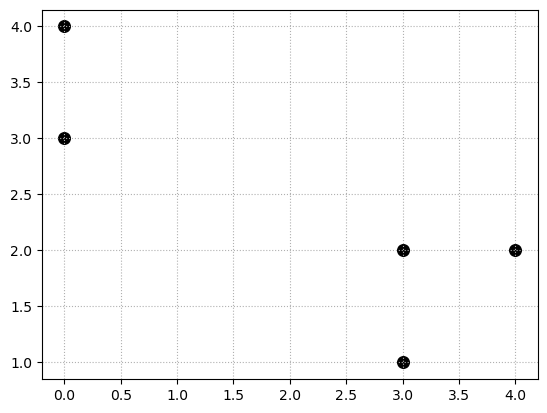

In [3]:
plt.scatter(X[:, 0], X[:, 1], c='black', s=70)
plt.grid(linestyle="dotted")
plt.show()

# Matriz de Afinidad a través de KNN

In [4]:
A_knn = kneighbors_graph(X, 2, mode='connectivity', include_self=True)
A_knn.toarray()

array([[1., 1., 0., 0., 0.],
       [1., 1., 0., 0., 0.],
       [0., 0., 1., 1., 0.],
       [0., 0., 1., 1., 0.],
       [0., 0., 0., 1., 1.]])

# Matriz de Afinidad a través del Kernel RBF

Primero se calcula la matriz de distancias entre todos los puntos:

In [5]:
dist = distance_matrix(X,X)
dist

array([[0.        , 1.        , 3.60555128, 3.16227766, 4.12310563],
       [1.        , 0.        , 4.24264069, 3.60555128, 4.47213595],
       [3.60555128, 4.24264069, 0.        , 1.        , 1.41421356],
       [3.16227766, 3.60555128, 1.        , 0.        , 1.        ],
       [4.12310563, 4.47213595, 1.41421356, 1.        , 0.        ]])

# Kernel

Una función $K:X\rightarrow\mathbb{R}$ es un kernel si existe $k:  [0,\infty[ \rightarrow \mathbb{R}$, tal que $K(x) = k( \| x \|^2 )$.

## Gaussian kernel (RBF) 

$K(x) = e^{-\frac{\| x \|^2}{2\sigma^2}}$, donde $\sigma$ es la desviación estándar.

Luego, se aplica el Kernel RBF sobre la matriz de distancias:

In [6]:
RBF(dist, sigma=1)

array([[1.  , 0.61, 0.  , 0.01, 0.  ],
       [0.61, 1.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 1.  , 0.61, 0.37],
       [0.01, 0.  , 0.61, 1.  , 0.61],
       [0.  , 0.  , 0.37, 0.61, 1.  ]])

# Laplaciano

El Laplaciano se calcula como $\mathcal{L}=\mathcal{D}-\mathcal{A}$, donde $\mathcal{D}$ es una matriz diagonal de la forma: 

$$
D_{i,j}:=\left\{
\begin{matrix} 
\deg(v_i) & \mbox{if}\ i = j \\
0 & \mbox{otherwise}
\end{matrix}\right.
$$

con $\deg(v_i) = \sum_{j=1}^n w_{i,j}$.

# Ejemplo Spectral Clustering

In [7]:
interact(plot_spectral_embedding, forma=["moons","rings","spiral"], k=(2,3), kernel=["rbf","nearest_neighbors"]);

interactive(children=(Dropdown(description='forma', options=('moons', 'rings', 'spiral'), value='moons'), IntS…

# Cluster Evaluation

## The Silhouette Coefficient

Evalúa cohesión y separación del cluster. Para el objeto $i$-ésimo:
    \begin{equation}
        \mathbf{s}_i = \frac{b_i-a_i}{\max{(a_i,b_i)}}, 
    \end{equation}
    
donde $a$ es la distancia promedio a todos los otros objetos en su propio cluster, y $b$ la distancia promedio a todos los objetos en el cluster más cercano.
    
$$ \text{(worst) } -1 \leq \mathbf{s}_i \leq 1 \text{ (best)} $$
    
$\mathbf{Silhouette}$ es el promedio de $\mathbf{s}_i$ sobre todos los objetos del conjunto de datos completo.
    
\begin{equation}
\mathbf{Silhouette} = \bar{\mathbf{s}}_i, \forall i.
\end{equation}

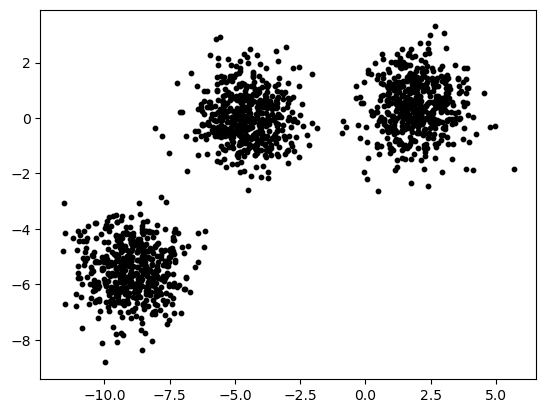

In [8]:
n_samples = 1500
random_state = 170
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X1,_ = make_blobs(n_samples=n_samples, random_state=random_state)
plt.scatter(X1[:, 0], X1[:, 1], c='black', s=10)
plt.show()

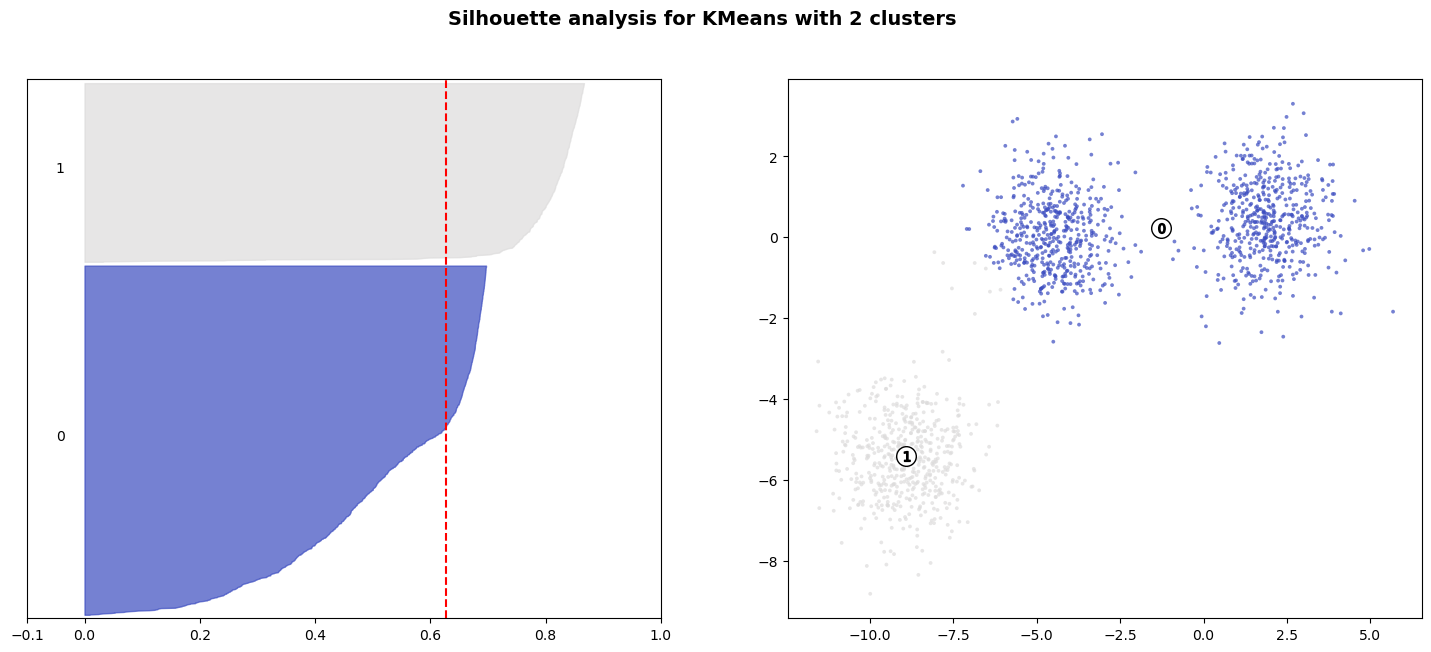

In [9]:
silhouette_kmeans(X1, k=2)

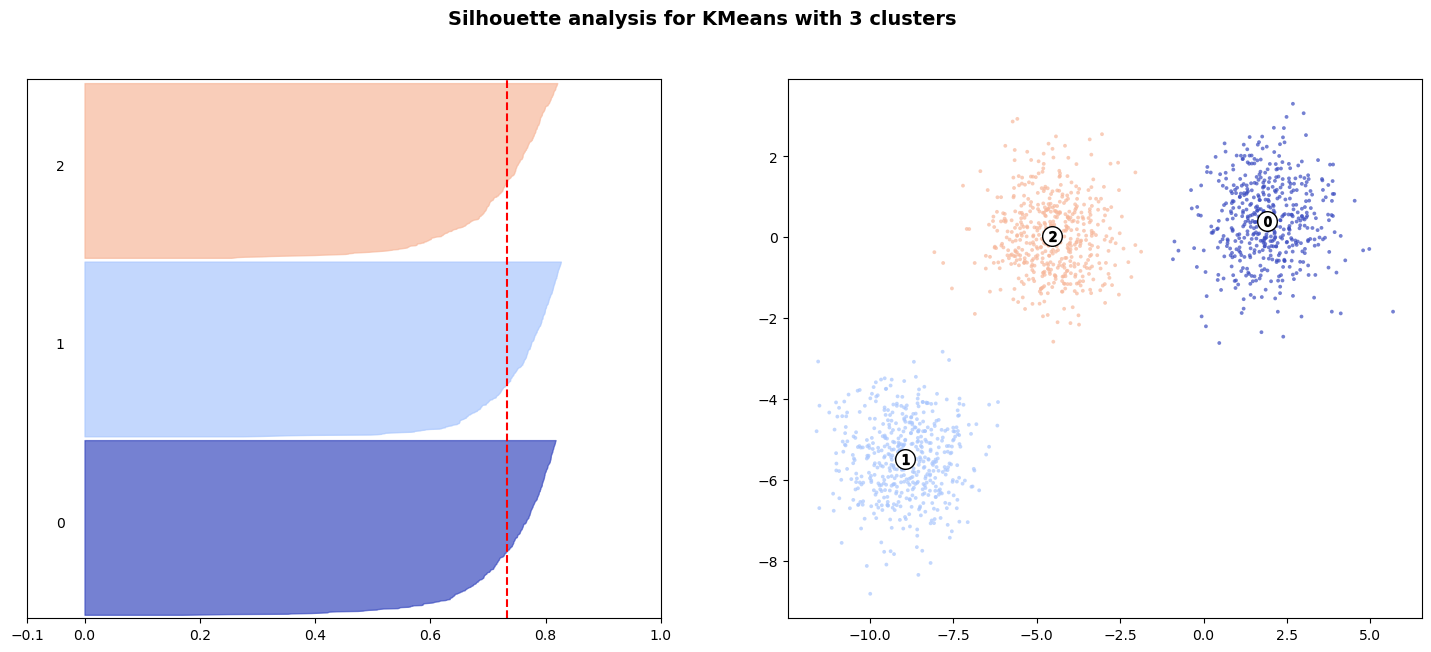

In [10]:
silhouette_kmeans(X1, k=3)

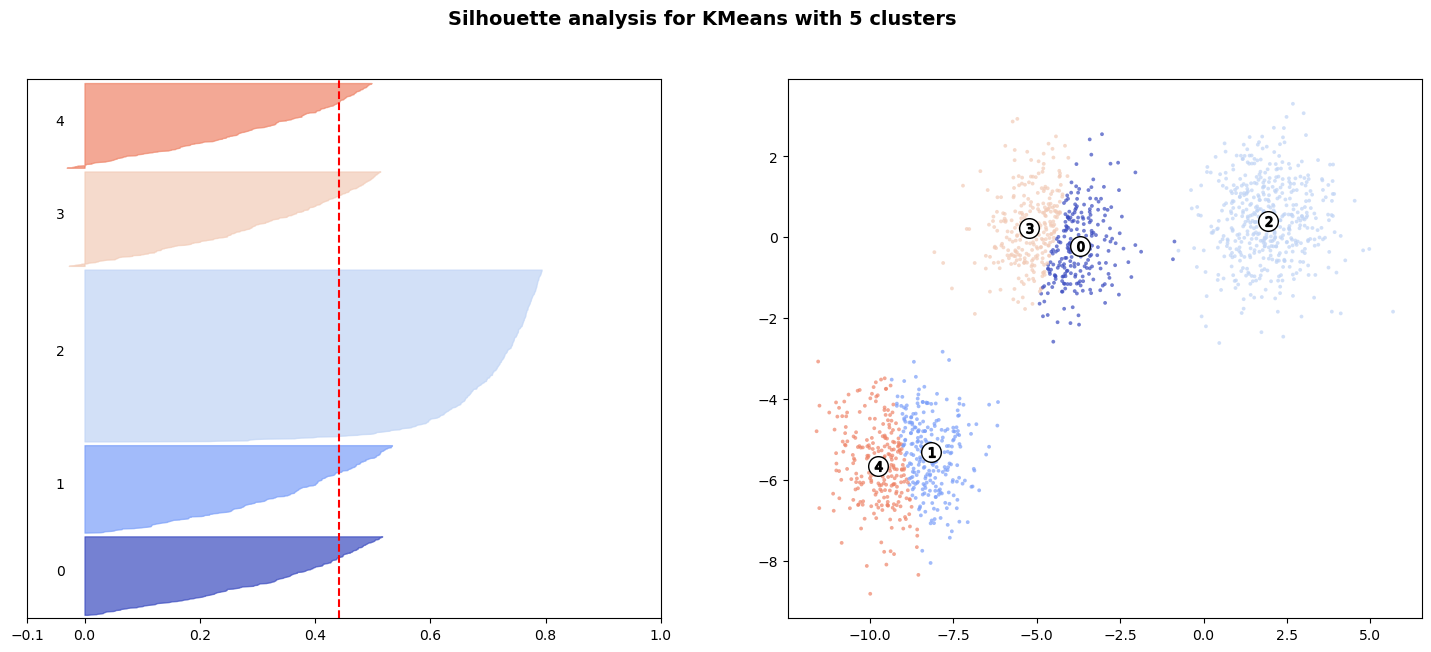

In [11]:
silhouette_kmeans(X1, k=5)